# Dermatology — Differential Diagnosis of Erythemato-Squamous Diseases

**Problem:** six skin diseases — psoriasis, seborrheic dermatitis, lichen planus, pityriasis rosea, chronic dermatitis and pityriasis rubra pilaris — look very similar: all show redness (erythema) and scaling. Doctors usually need a **skin biopsy** to tell them apart.

**Data:** 366 patients from Gazi University, Ankara (UCI Machine Learning Repository).
Each patient has **12 clinical features** (observed by the doctor, e.g. itching, scalp involvement, age) and **22 histopathological features** (seen under the microscope after a biopsy). Most features are graded 0–3.

**Questions**
1. Which features distinguish each disease?
2. Which classifier diagnoses most accurately?
3. **Can the diseases be diagnosed from clinical features alone, without a biopsy?**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import confusion_matrix, classification_report

sns.set_theme(style="whitegrid", context="notebook")
PALETTE = ["#2a6f97", "#e07a5f", "#81b29a", "#f2cc8f", "#3d405b", "#9c89b8"]
FIG = "figures/"
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

## 1. Data overview & quality checks

In [2]:
CLINICAL = ["erythema", "scaling", "definite_borders", "itching", "koebner_phenomenon", "polygonal_papules",
            "follicular_papules", "oral_mucosal_involvement", "knee_and_elbow_involvement", "scalp_involvement",
            "family_history"]
HISTO = ["melanin_incontinence", "eosinophils_in_infiltrate", "PNL_infiltrate", "fibrosis_of_papillary_dermis",
         "exocytosis", "acanthosis", "hyperkeratosis", "parakeratosis", "clubbing_of_rete_ridges",
         "elongation_of_rete_ridges", "thinning_of_suprapapillary_epidermis", "spongiform_pustule",
         "munro_microabcess", "focal_hypergranulosis", "disappearance_of_granular_layer",
         "vacuolisation_of_basal_layer", "spongiosis", "saw_tooth_appearance_of_retes", "follicular_horn_plug",
         "perifollicular_parakeratosis", "inflammatory_mononuclear_infiltrate", "band_like_infiltrate"]
DISEASES = {1: "Psoriasis", 2: "Seborrheic dermatitis", 3: "Lichen planus",
            4: "Pityriasis rosea", 5: "Chronic dermatitis", 6: "Pityriasis rubra pilaris"}

df = pd.read_csv("data/dermatology.data", header=None, names=CLINICAL + HISTO + ["age", "disease_code"], na_values="?")
df["disease"] = df["disease_code"].map(DISEASES)
CLINICAL_ALL = CLINICAL + ["age"]          # age is recorded at the clinical exam
FEATURES = CLINICAL_ALL + HISTO
print(f"{len(df)} patients · {len(CLINICAL_ALL)} clinical + {len(HISTO)} histopathological features")
df.head()

366 patients · 12 clinical + 22 histopathological features


,erythema,scaling,definite_borders,itching,koebner_phenomenon,polygonal_papules,follicular_papules,oral_mucosal_involvement,knee_and_elbow_involvement,scalp_involvement,family_history,melanin_incontinence,eosinophils_in_infiltrate,PNL_infiltrate,fibrosis_of_papillary_dermis,exocytosis,acanthosis,hyperkeratosis,parakeratosis,clubbing_of_rete_ridges,elongation_of_rete_ridges,thinning_of_suprapapillary_epidermis,spongiform_pustule,munro_microabcess,focal_hypergranulosis,disappearance_of_granular_layer,vacuolisation_of_basal_layer,spongiosis,saw_tooth_appearance_of_retes,follicular_horn_plug,perifollicular_parakeratosis,inflammatory_mononuclear_infiltrate,band_like_infiltrate,age,disease_code,disease
0,2,2,0,3,0,0,0,0,1,0,0,0,0,0,0,3,2,0,0,0,0,0,0,0,0,0,0,3,0,0,0,1,0,55.000,2,Seborrheic dermatitis
1,3,3,3,2,1,0,0,0,1,1,1,0,0,1,0,1,2,0,2,2,2,2,2,1,0,0,0,0,0,0,0,1,0,8.000,1,Psoriasis
2,2,1,2,3,1,3,0,3,0,0,0,1,0,0,0,1,2,0,2,0,0,0,0,0,2,0,2,3,2,0,0,2,3,26.000,3,Lichen planus
3,2,2,2,0,0,0,0,0,3,2,0,0,0,3,0,0,2,0,3,2,2,2,2,0,0,3,0,0,0,0,0,3,0,40.000,1,Psoriasis
4,2,3,2,2,2,2,0,2,0,0,0,1,0,0,0,1,2,0,0,0,0,0,0,0,2,2,3,2,3,0,0,2,3,45.000,3,Lichen planus


In [3]:
print("Missing values:", df[FEATURES].isnull().sum()[lambda s: s > 0].to_dict())
print("Duplicate patients:", df.duplicated().sum())
print("Feature range (graded features):", int(df[FEATURES].drop(columns="age").min().min()), "–", int(df[FEATURES].drop(columns="age").max().max()))

Missing values: {'age': 8}
Duplicate patients: 0
Feature range (graded features): 0 – 3


**Data quality.** Only 8 patients (2%) have a missing age. Instead of deleting these patients — which would remove 4 of the 52 chronic dermatitis cases — age is **imputed with the median inside the modeling pipeline**, learned from training folds only. There are no duplicates and all graded features are within 0–3.

## 2. Exploratory analysis

### 2.1 How common is each disease?

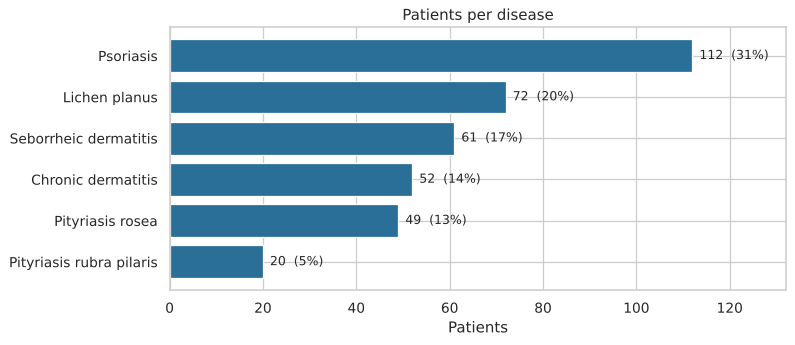

In [4]:
counts = df["disease"].value_counts()
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(counts.index[::-1], counts.values[::-1], color=PALETTE[0])
for i, v in enumerate(counts.values[::-1]):
    ax.text(v + 1.5, i, f"{v}  ({v / len(df):.0%})", va="center", fontsize=10)
ax.set(title="Patients per disease", xlabel="Patients", xlim=(0, counts.max() * 1.18))
plt.tight_layout(); plt.savefig(FIG + "01_class_distribution.png", dpi=150); plt.show()

The classes are imbalanced: psoriasis is 5.6× more common than pityriasis rubra pilaris. For this reason models are compared with **macro F1** (every disease counts equally), not only accuracy, and all splits are **stratified**.

### 2.2 Age

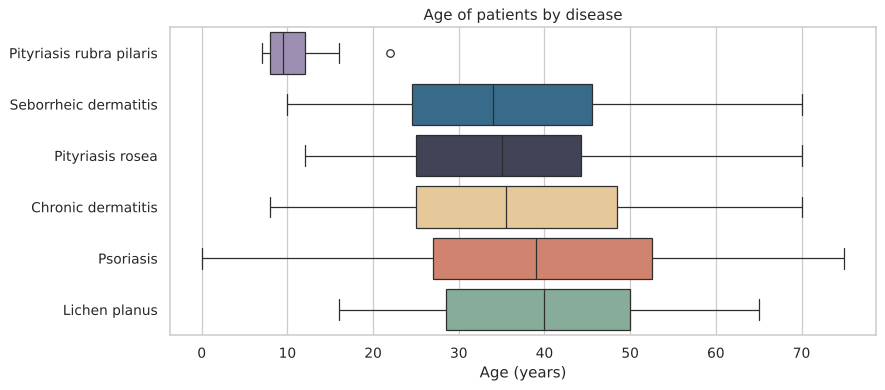

,count,median,min,max
disease,,,,
Pityriasis rubra pilaris,20.000,9.500,7.000,22.000
Seborrheic dermatitis,60.000,34.000,10.000,70.000
Pityriasis rosea,48.000,35.000,12.000,70.000
Chronic dermatitis,48.000,35.500,8.000,70.000
Psoriasis,111.000,39.000,0.000,75.000
Lichen planus,71.000,40.000,16.000,65.000


In [5]:
order = df.groupby("disease")["age"].median().sort_values().index
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.boxplot(data=df, x="age", y="disease", order=order, hue="disease", palette=PALETTE, legend=False, ax=ax)
ax.set(title="Age of patients by disease", xlabel="Age (years)", ylabel="")
plt.tight_layout(); plt.savefig(FIG + "02_age_by_disease.png", dpi=150); plt.show()
df.groupby("disease")["age"].describe()[["count", "50%", "min", "max"]].rename(columns={"50%": "median"}).loc[order]

**Pityriasis rubra pilaris** stands out as a disease of children and young people (median age about 10), which makes age a useful clinical clue.

### 2.3 Disease profiles: which features define each disease?

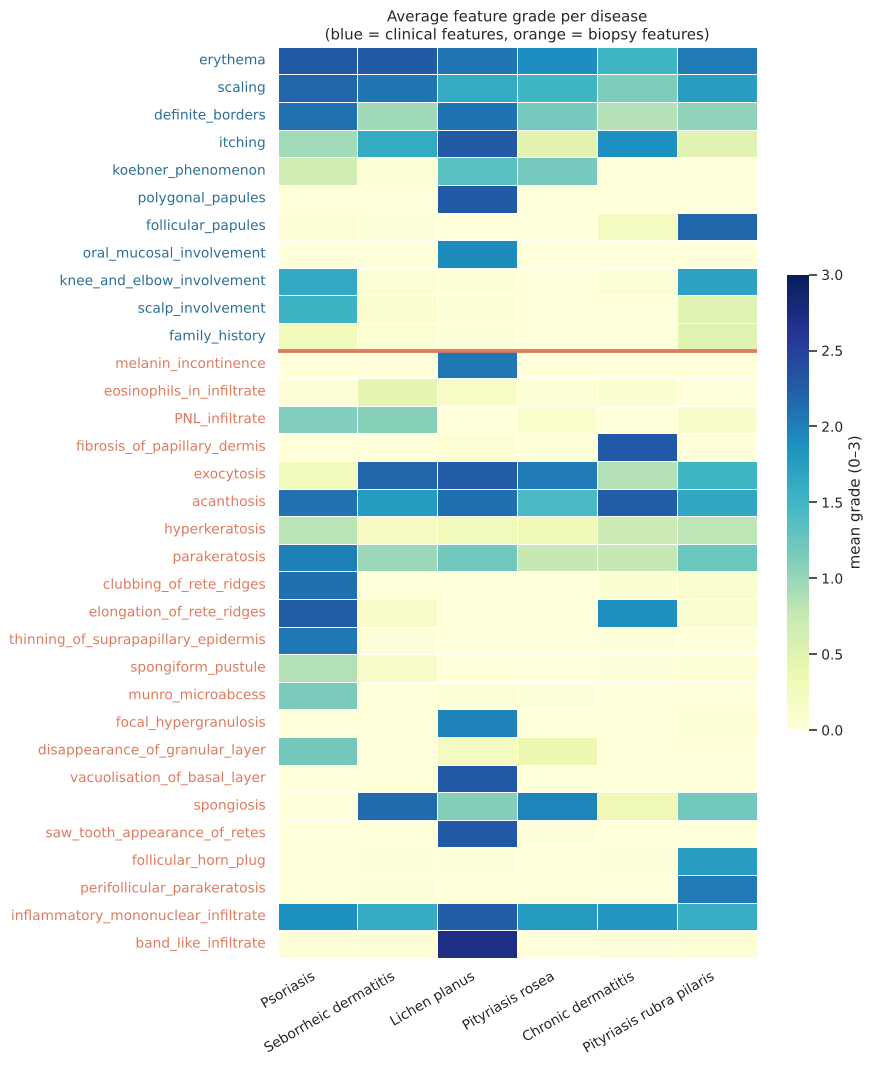

In [6]:
profile = df.groupby("disease")[CLINICAL + HISTO].mean().T[list(DISEASES.values())]
fig, ax = plt.subplots(figsize=(10, 12))
sns.heatmap(profile, cmap="YlGnBu", vmin=0, vmax=3, linewidths=0.4, cbar_kws={"label": "mean grade (0–3)", "shrink": 0.5}, ax=ax)
ax.axhline(len(CLINICAL), color="#e07a5f", lw=3)
for lbl in ax.get_yticklabels():
    lbl.set_color(PALETTE[0] if lbl.get_text() in CLINICAL else PALETTE[1])
ax.set(title="Average feature grade per disease\n(blue = clinical features, orange = biopsy features)", xlabel="", ylabel="")
plt.xticks(rotation=30, ha="right")
plt.tight_layout(); plt.savefig(FIG + "03_disease_profiles.png", dpi=150); plt.show()

In [7]:
signature = {}
for disease in profile.columns:
    others = profile.drop(columns=disease).max(axis=1)
    gap = (profile[disease] - others).sort_values(ascending=False)
    signature[disease] = ", ".join(f"{f} (+{g:.1f})" for f, g in gap.head(3).items() if g > 0.3) or "no single distinctive feature"
pd.Series(signature, name="most distinctive features (grade above any other disease)").to_frame()

,most distinctive features (grade above any other disease)
Psoriasis,"thinning_of_suprapapillary_epidermis (+2.0), clubbing_of_rete_ridges (+2.0), munro_microabcess (+1.1)"
Seborrheic dermatitis,no single distinctive feature
Lichen planus,"band_like_infiltrate (+2.7), vacuolisation_of_basal_layer (+2.3), polygonal_papules (+2.3)"
Pityriasis rosea,no single distinctive feature
Chronic dermatitis,fibrosis_of_papillary_dermis (+2.2)
Pityriasis rubra pilaris,"perifollicular_parakeratosis (+2.0), follicular_papules (+2.0), follicular_horn_plug (+1.7)"


Most diseases have a clear **signature**, e.g. lichen planus → band-like infiltrate, polygonal papules, saw-tooth retes; pityriasis rubra pilaris → follicular papules and follicular horn plug. **Seborrheic dermatitis and pityriasis rosea** have no strong unique feature — they are the pair most likely to be confused.

### 2.4 Most informative features

11 of the top 15 features come from the biopsy.


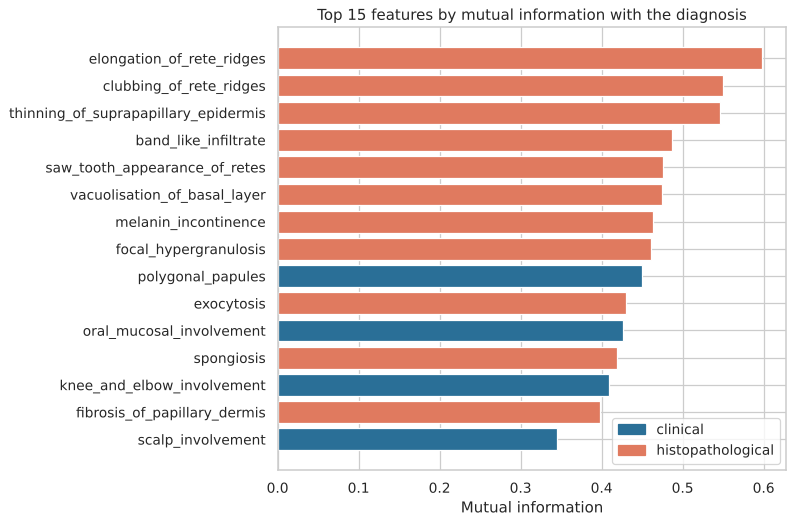

In [8]:
X_imp = df[FEATURES].fillna(df["age"].median())
mi = pd.Series(mutual_info_classif(X_imp, df["disease_code"], discrete_features=[f != "age" for f in FEATURES], random_state=0),
               index=FEATURES).sort_values()
top = mi.tail(15)
colors = [PALETTE[1] if f in HISTO else PALETTE[0] for f in top.index]
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top.index, top.values, color=colors)
ax.set(title="Top 15 features by mutual information with the diagnosis", xlabel="Mutual information")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=PALETTE[0], label="clinical"), Patch(color=PALETTE[1], label="histopathological")], loc="lower right")
plt.tight_layout(); plt.savefig(FIG + "04_feature_information.png", dpi=150); plt.show()
print(f"{sum(f in HISTO for f in top.index)} of the top 15 features come from the biopsy.")

## 3. Modeling

**Setup**
- Six classifiers, each in a pipeline: median imputation of age → scaling (where the algorithm needs it) → model.
- With only 366 patients, a single 80/20 split gives a noisy estimate (73 test patients). Models are therefore compared with **10-fold stratified cross-validation, repeated 3 times** (30 train/test splits).
- Hyperparameters (k for KNN, C for SVM and logistic regression, depth for the tree) are tuned **inside each training fold** (nested CV), so the reported scores are not optimistic.

In [9]:
def pipe(model, scale=True):
    steps = [("impute", SimpleImputer(strategy="median"))] + ([("scale", StandardScaler())] if scale else []) + [("model", model)]
    return Pipeline(steps)

inner = StratifiedKFold(5, shuffle=True, random_state=1)
MODELS = {
    "Logistic regression": GridSearchCV(pipe(LogisticRegression(max_iter=5000)), {"model__C": [0.01, 0.1, 1, 10]}, cv=inner),
    "SVM (linear)":        GridSearchCV(pipe(SVC(kernel="linear")), {"model__C": [0.001, 0.01, 0.1, 1]}, cv=inner),
    "Random forest":       pipe(RandomForestClassifier(n_estimators=300, random_state=0), scale=False),
    "KNN":                 GridSearchCV(pipe(KNeighborsClassifier()), {"model__n_neighbors": [3, 5, 7, 9, 11, 15]}, cv=inner),
    "Naive Bayes":         pipe(GaussianNB(), scale=False),
    "Decision tree":       GridSearchCV(pipe(DecisionTreeClassifier(random_state=0), scale=False),
                                        {"model__max_depth": [3, 5, 8, None], "model__min_samples_leaf": [1, 3, 5]}, cv=inner),
}

def cv_scores(feature_set):
    X, y = df[feature_set], df["disease_code"]
    rows = {}
    for name, model in MODELS.items():
        accs, f1s = [], []
        for rep in range(3):
            outer = StratifiedKFold(10, shuffle=True, random_state=rep)
            s = cross_validate(model, X, y, cv=outer, scoring=["accuracy", "f1_macro"], n_jobs=-1)
            accs += list(s["test_accuracy"]); f1s += list(s["test_f1_macro"])
        rows[name] = {"accuracy": np.mean(accs), "accuracy_std": np.std(accs), "macro_F1": np.mean(f1s), "macro_F1_std": np.std(f1s)}
    return pd.DataFrame(rows).T.sort_values("macro_F1", ascending=False)

all_feats = cv_scores(FEATURES)
all_feats.style.format("{:.3f}")

,accuracy,accuracy_std,macro_F1,macro_F1_std
Random forest,0.977,0.021,0.975,0.024
SVM (linear),0.973,0.022,0.969,0.025
Logistic regression,0.972,0.021,0.967,0.025
KNN,0.961,0.027,0.959,0.028
Decision tree,0.944,0.038,0.928,0.052
Naive Bayes,0.875,0.030,0.838,0.044


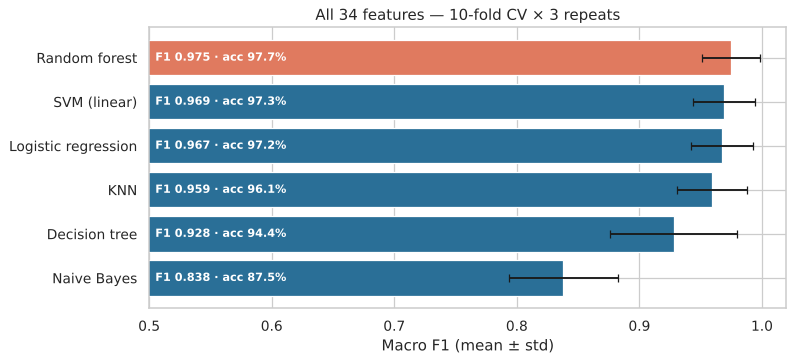

In [10]:
fig, ax = plt.subplots(figsize=(9, 4.2))
t = all_feats.iloc[::-1]
colors = [PALETTE[1] if n == all_feats.index[0] else PALETTE[0] for n in t.index]
ax.barh(t.index, t["macro_F1"], xerr=t["macro_F1_std"], color=colors, capsize=3)
for i, (v, a) in enumerate(zip(t["macro_F1"], t["accuracy"])):
    ax.text(0.505, i, f"F1 {v:.3f} · acc {a:.1%}", va="center", fontsize=9, color="white", weight="bold")
ax.set(title="All 34 features — 10-fold CV × 3 repeats", xlabel="Macro F1 (mean ± std)", xlim=(0.5, 1.02))
plt.tight_layout(); plt.savefig(FIG + "05_model_comparison.png", dpi=150); plt.show()

## 4. Can we diagnose without a biopsy?

The same six models are trained on three feature sets: **clinical only** (12 features available at a normal doctor's visit), **histopathological only** (22 biopsy features) and **all features**.

In [11]:
clin = cv_scores(CLINICAL_ALL)
hist = cv_scores(HISTO)
comparison = pd.DataFrame({
    "Clinical only (12)": clin["macro_F1"],
    "Biopsy only (22)": hist["macro_F1"],
    "All features (34)": all_feats["macro_F1"],
}).loc[all_feats.index]
comparison.style.format("{:.3f}").background_gradient(cmap="YlGnBu", vmin=0.5, vmax=1.0, axis=None)

,Clinical only (12),Biopsy only (22),All features (34)
Random forest,0.850,0.931,0.975
SVM (linear),0.888,0.934,0.969
Logistic regression,0.867,0.937,0.967
KNN,0.813,0.919,0.959
Decision tree,0.780,0.905,0.928
Naive Bayes,0.676,0.831,0.838


Best clinical-only model: SVM (linear) — macro F1 0.888, accuracy 89.1%
Best biopsy-only model:   Logistic regression — macro F1 0.937
Best with all features:   Random forest — macro F1 0.975, accuracy 97.7%


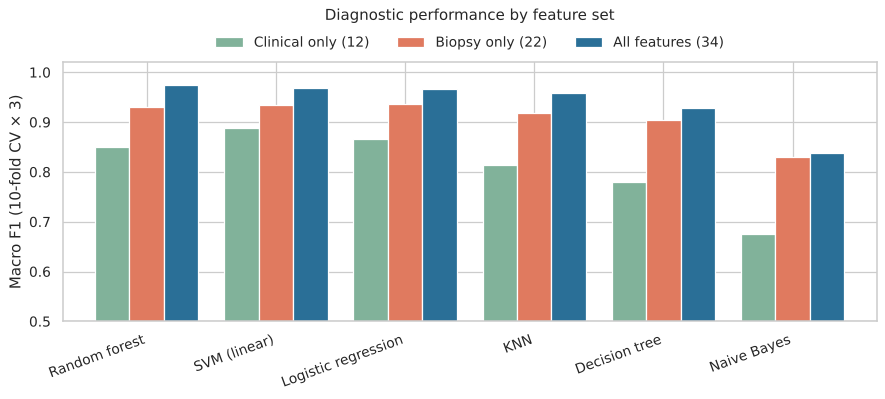

In [12]:
fig, ax = plt.subplots(figsize=(10, 4.6))
comparison.plot.bar(ax=ax, color=[PALETTE[2], PALETTE[1], PALETTE[0]], width=0.8, edgecolor="white")
ax.set(ylabel="Macro F1 (10-fold CV × 3)", xlabel="", ylim=(0.5, 1.02))
ax.set_title("Diagnostic performance by feature set", pad=34)
plt.xticks(rotation=20, ha="right"); ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=3, frameon=False)
plt.tight_layout(); plt.savefig(FIG + "06_clinical_vs_biopsy.png", dpi=150); plt.show()
best_clin = clin["macro_F1"].idxmax()
print(f"Best clinical-only model: {best_clin} — macro F1 {clin.loc[best_clin, 'macro_F1']:.3f}, accuracy {clin.loc[best_clin, 'accuracy']:.1%}")
print(f"Best biopsy-only model:   {hist['macro_F1'].idxmax()} — macro F1 {hist['macro_F1'].max():.3f}")
print(f"Best with all features:   {all_feats.index[0]} — macro F1 {all_feats['macro_F1'].iloc[0]:.3f}, accuracy {all_feats['accuracy'].iloc[0]:.1%}")

In [13]:
y = df["disease_code"]
pred_clin = cross_val_predict(MODELS[best_clin], df[CLINICAL_ALL], y, cv=StratifiedKFold(10, shuffle=True, random_state=0))
recall_clin = pd.Series(classification_report(y, pred_clin, output_dict=True, zero_division=0)).iloc[:6]
recall_clin = pd.Series({DISEASES[int(k)]: v["recall"] for k, v in recall_clin.items()}, name="recall (clinical only)")
recall_clin.sort_values().to_frame()

,recall (clinical only)
Pityriasis rosea,0.776
Chronic dermatitis,0.827
Seborrheic dermatitis,0.852
Psoriasis,0.911
Lichen planus,0.972
Pityriasis rubra pilaris,1.000


## 5. Best model: where does it still make mistakes?

9 misdiagnosed patients out of 366 (2.5%).
Most frequent confusions: Pityriasis rosea → Seborrheic dermatitis: 5; Seborrheic dermatitis → Pityriasis rosea: 3; Seborrheic dermatitis → Psoriasis: 1


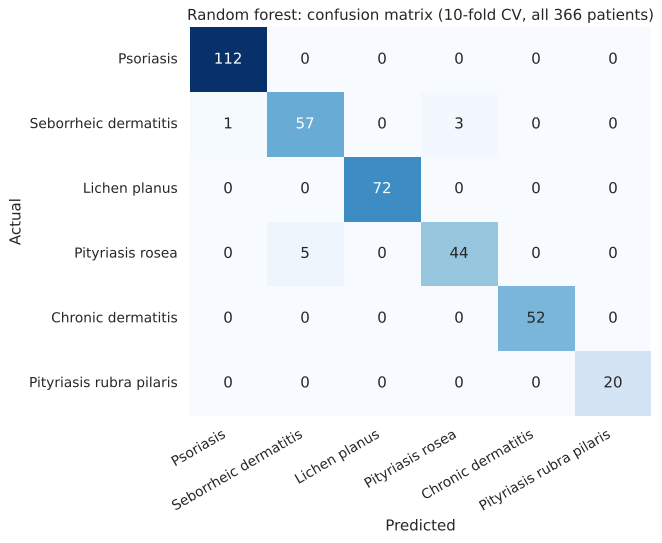

In [14]:
best_name = all_feats.index[0]
pred = cross_val_predict(MODELS[best_name], df[FEATURES], y, cv=StratifiedKFold(10, shuffle=True, random_state=0))
names = list(DISEASES.values())
cm = confusion_matrix(y, pred, labels=list(DISEASES))
fig, ax = plt.subplots(figsize=(7.5, 6.2))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, xticklabels=names, yticklabels=names, ax=ax)
ax.set(title=f"{best_name}: confusion matrix (10-fold CV, all 366 patients)", xlabel="Predicted", ylabel="Actual")
plt.xticks(rotation=30, ha="right"); plt.yticks(rotation=0)
plt.tight_layout(); plt.savefig(FIG + "07_confusion_matrix.png", dpi=150); plt.show()
errors = int((pred != y).sum())
print(f"{errors} misdiagnosed patients out of {len(y)} ({errors / len(y):.1%}).")
off = pd.DataFrame(cm, index=names, columns=names).stack()
off = off[[a != b for a, b in off.index]].sort_values(ascending=False)
print("Most frequent confusions:", "; ".join(f"{a} → {b}: {n}" for (a, b), n in off.head(3).items() if n > 0))

## 6. Key findings

In [15]:
print(f"1. Near-perfect diagnosis with all features: {best_name}, accuracy {all_feats['accuracy'].iloc[0]:.1%}, macro F1 {all_feats['macro_F1'].iloc[0]:.3f} "
      f"({errors} errors in {len(y)} patients). Simple linear models are as good as complex ones.")
print(f"2. The biopsy carries most of the signal: biopsy-only models reach macro F1 {hist['macro_F1'].max():.3f}, "
      f"clinical-only models {clin['macro_F1'].max():.3f}; {sum(f in HISTO for f in top.index)} of the 15 most informative features are histopathological.")
print(f"3. Without a biopsy, accuracy drops to {clin.loc[best_clin, 'accuracy']:.0%}; the weakest diagnosis is "
      f"{recall_clin.idxmin()} (recall {recall_clin.min():.0%}) — a clinical-only model could be used for triage, not final diagnosis.")
print("4. Seborrheic dermatitis and pityriasis rosea are the hardest pair — they have no strong unique feature.")
print("5. Pityriasis rubra pilaris mainly affects children and young people, so age is a useful clinical clue.")

1. Near-perfect diagnosis with all features: Random forest, accuracy 97.7%, macro F1 0.975 (9 errors in 366 patients). Simple linear models are as good as complex ones.
2. The biopsy carries most of the signal: biopsy-only models reach macro F1 0.937, clinical-only models 0.888; 11 of the 15 most informative features are histopathological.
3. Without a biopsy, accuracy drops to 89%; the weakest diagnosis is Pityriasis rosea (recall 78%) — a clinical-only model could be used for triage, not final diagnosis.
4. Seborrheic dermatitis and pityriasis rosea are the hardest pair — they have no strong unique feature.
5. Pityriasis rubra pilaris mainly affects children and young people, so age is a useful clinical clue.


*This is an analysis of a public research dataset, not a medical tool.*